# 03 Multi-Class Classification: Attack Category Attribution

**Project:** Network Intrusion Detection Using Machine Learning  
**Task:** Multi-Class Classification (`attack_cat`: Normal and 9 attack categories: Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms)  

This notebook implements, benchmarks, tunes, and evaluates multi-class models for network traffic categorization:
1. **Logistic Regression** (multinomial with balanced class weights)
2. **Decision Tree** (CART with balanced class weights)
3. **Random Forest** (ensemble with balanced class weights)
4. **K-Nearest Neighbors (KNN)** (instance-based classification)
5. **Naive Bayes** (GaussianNB)
6. **XGBoost** (gradient boosted decision trees with balanced sample weights)
7. **Support Vector Machine** (SVM on a representative stratified sample)

### Pipeline Steps:
- Load clean Parquet splits (`train_cleaned.parquet`, `test_cleaned.parquet`)
- Feature transformation with saved `ColumnTransformer` (194 columns) and top-30 feature selector
- Class imbalance analysis across the 10 categories
- Stratified 5-fold cross-validation across all candidate algorithms
- Hyperparameter tuning for top models (`Random Forest`, `XGBoost`, `Decision Tree`) by Macro-F1
- Evaluation on held-out test set (55,945 records)
- Model selection and persistence to `models/best_multiclass.joblib`
- Detailed per-class breakdown and analysis of rare attack categories (Worms, Shellcode, Backdoor, Analysis)
- Normalized confusion matrix heatmap visualization
- Verification of the inference cascade contract on `data/sample/sample_input.csv`

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import joblib
from IPython.display import Image, display

# Ensure project root is in sys.path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config, data_loader, preprocess, features, models, train, evaluate

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
print('Environment and modules loaded successfully.')

Environment and modules loaded successfully.


## 1. Load Processed Splits and Inspect Class Imbalance

We load the deduplicated, cleaned training and testing datasets and examine the distribution of `attack_cat`.  
Note the severe class skew: Normal accounts for 48.2% of the training set, while rare attack classes like **Worms** comprise only 127 records (0.12%) and **Shellcode** comprises 1,091 records (1.01%).

In [2]:
train_df, test_df = data_loader.load_processed()

train_counts = train_df[config.MULTI_TARGET].value_counts()
train_pct = (train_df[config.MULTI_TARGET].value_counts(normalize=True) * 100).round(2)
test_counts = test_df[config.MULTI_TARGET].value_counts()
test_pct = (test_df[config.MULTI_TARGET].value_counts(normalize=True) * 100).round(2)

df_dist = pd.DataFrame({
    'Train Count': train_counts,
    'Train %': train_pct,
    'Test Count': test_counts,
    'Test %': test_pct,
})
display(df_dist)

2026-10-29 01:51:51,335 [INFO] Loading cleaned datasets from Parquet: C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\train_cleaned.parquet, C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\test_cleaned.parquet


,Train Count,Train %,Test Count,Test %
attack_cat,,,,
Analysis,1594,1.48,446,0.80
Backdoor,1535,1.42,346,0.62
DoS,3806,3.53,1718,3.07
Exploits,19844,18.42,7609,13.60
Fuzzers,16150,14.99,4838,8.65
Generic,4181,3.88,3657,6.54
Normal,51890,48.16,34206,61.14
Reconnaissance,7522,6.98,2703,4.83
Shellcode,1091,1.01,378,0.68


## 2. Feature Transformation & Selection

Using the leak-free artifacts saved during Phase 2 (`models/preprocessor.joblib` and `models/selected_features.json`), we transform the raw features into standardized numeric representations and slice to the top 30 most predictive features.

In [3]:
preprocessor = preprocess.load_preprocessor()
feature_cols = preprocess.load_feature_columns()
selected_features = features.load_selected_features()
all_feature_names = preprocessor.get_feature_names_out().tolist()

print(f'Total input columns: {len(feature_cols)}')
print(f'Transformed feature space: {len(all_feature_names)} columns')
print(f'Selected feature subset: {len(selected_features)} features')

X_train_full = preprocess.transform_features(preprocessor, train_df[feature_cols])
X_train_sel = features.filter_features(X_train_full, all_feature_names, selected_features)
y_train = np.asarray(train_df[config.MULTI_TARGET], dtype=str)

X_test_full = preprocess.transform_features(preprocessor, test_df[feature_cols])
X_test_sel = features.filter_features(X_test_full, all_feature_names, selected_features)
y_test = np.asarray(test_df[config.MULTI_TARGET], dtype=str)

print(f'X_train_sel shape: {X_train_sel.shape}, y_train shape: {y_train.shape}')
print(f'X_test_sel shape: {X_test_sel.shape}, y_test shape: {y_test.shape}')

Total input columns: 42
Transformed feature space: 194 columns
Selected feature subset: 30 features


X_train_sel shape: (107740, 30), y_train shape: (107740,)
X_test_sel shape: (55945, 30), y_test shape: (55945,)


## 3. Stratified 5-Fold Cross-Validation Across Candidate Models

We evaluate all seven algorithms using stratified 5-fold cross-validation.  
Per `rules.md`, we prioritize **Macro-F1** and **Macro-Recall** over raw accuracy to prevent the majority Normal class from masking poor performance on critical rare attacks.

,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,XGBoost,0.7710,0.5705,0.7123,0.6001,0.7947
1,Random Forest,0.7752,0.5738,0.6810,0.5970,0.7992
2,Decision Tree,0.7677,0.5622,0.6787,0.5877,0.7911
3,KNN,0.7404,0.5302,0.4306,0.4512,0.7434
4,Logistic Regression,0.6567,0.4203,0.5301,0.4021,0.7062
5,SVM (Sampled),0.7113,0.4053,0.3678,0.3454,0.7059
6,Naive Bayes,0.5236,0.3446,0.4054,0.2895,0.5939


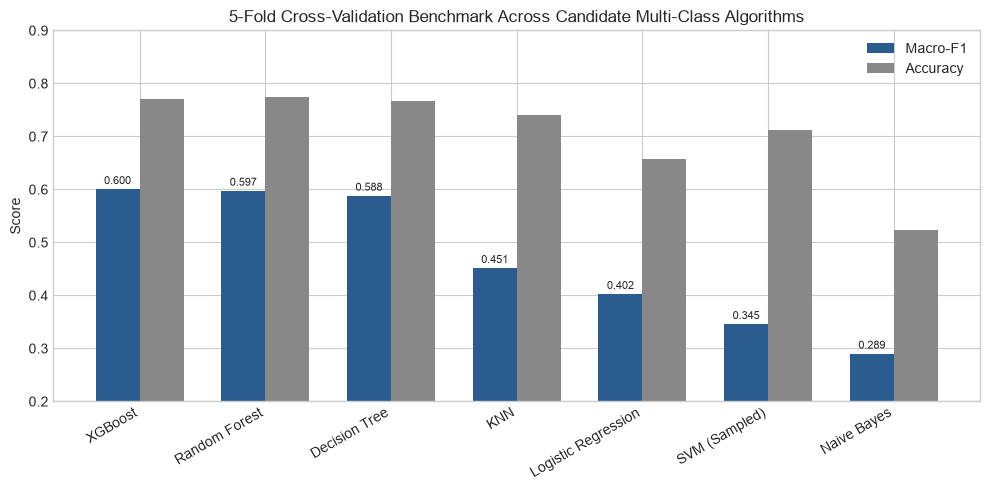

In [4]:
cv_results_path = config.REPORTS_DIR / 'multiclass_cv_results.csv'
if cv_results_path.exists():
    df_cv = pd.read_csv(cv_results_path)
else:
    df_cv = train.evaluate_cv_multiclass_models(X_train_sel, y_train, cv_splits=5)
    df_cv.to_csv(cv_results_path, index=False)

display(df_cv)

# Plot Cross-Validation Macro-F1 vs Accuracy
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_cv))
width = 0.35

ax.bar(x - width/2, df_cv['f1_macro'], width, label='Macro-F1', color='#2b5c8f')
ax.bar(x + width/2, df_cv['accuracy'], width, label='Accuracy', color='#888888')

ax.set_ylabel('Score')
ax.set_title('5-Fold Cross-Validation Benchmark Across Candidate Multi-Class Algorithms')
ax.set_xticks(x)
ax.set_xticklabels(df_cv['model'], rotation=30, ha='right')
ax.set_ylim([0.2, 0.9])
ax.legend()

for i, v in enumerate(df_cv['f1_macro']):
    ax.text(i - width/2, v + 0.01, f'{v:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

## 4. Hyperparameter Tuning of Leading Algorithms

Based on cross-validation performance, the top three algorithms (`Random Forest`, `XGBoost`, and `Decision Tree`) were tuned using `RandomizedSearchCV` optimizing for Macro-F1.

In [5]:
tuning_results_path = config.REPORTS_DIR / 'multiclass_tuning_results.csv'
if tuning_results_path.exists():
    df_tuned = pd.read_csv(tuning_results_path)
else:
    top_models = ['Random Forest', 'XGBoost', 'Decision Tree']
    tuned_results = []
    for model_name in top_models:
        best_estimator, best_params, best_score = train.tune_multiclass_model(
            model_name,
            X_train_sel,
            y_train,
            n_iter=6,
            cv_splits=3,
        )
        tuned_results.append({
            'model': f'{model_name} (Tuned)',
            'best_cv_macro_f1': round(best_score, 4),
            'best_params': str(best_params),
        })
    df_tuned = pd.DataFrame(tuned_results)
    df_tuned.to_csv(tuning_results_path, index=False)

display(df_tuned)

,model,best_cv_macro_f1,best_params
0,XGBoost (Tuned),0.6018,"{'subsample': 1.0, 'n_estimators': 150, 'max_d..."
1,Random Forest (Tuned),0.5987,"{'n_estimators': 100, 'min_samples_split': 5, ..."
2,Decision Tree (Tuned),0.5806,"{'min_samples_split': 5, 'min_samples_leaf': 1..."


## 5. Independent Test Set Evaluation & Model Selection

Every candidate baseline model and tuned model is fitted on the full training set (107,740 records) and evaluated on the independent held-out test set (55,945 records).  
The benchmark comparison table is saved to `reports/multiclass_comparison.csv`.

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,model
0,0.6540,0.5042,0.6736,0.5230,0.8551,0.6540,0.7098,Random Forest (Tuned)
1,0.6448,0.4891,0.6748,0.5086,0.8541,0.6448,0.7027,Random Forest
2,0.6401,0.4868,0.6973,0.5067,0.8543,0.6401,0.7002,XGBoost (Tuned)
3,0.6471,0.4817,0.6528,0.5046,0.8321,0.6471,0.7016,Decision Tree (Tuned)
4,0.6375,0.4854,0.6970,0.5037,0.8551,0.6375,0.6986,XGBoost
5,0.6119,0.4547,0.6479,0.4801,0.8256,0.6119,0.6718,Decision Tree
6,0.6748,0.4562,0.4194,0.4074,0.7692,0.6748,0.7060,KNN
7,0.5616,0.3255,0.4644,0.3092,0.7965,0.5616,0.6310,Logistic Regression
8,0.5919,0.3672,0.3241,0.2767,0.7785,0.5919,0.6261,SVM (Sampled)
9,0.4445,0.2930,0.3633,0.2270,0.7782,0.4445,0.5559,Naive Bayes


C:\Users\Ankit007\AppData\Local\Temp\ipykernel_13700\881498391.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_comp, x='model', y='f1_macro', palette='Blues_r')


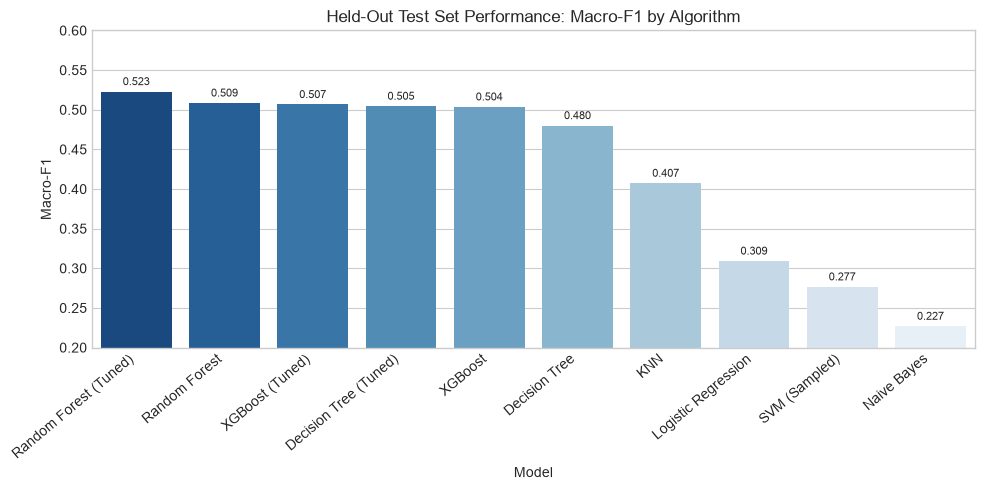

In [6]:
df_comp = pd.read_csv(config.MULTICLASS_COMPARISON_PATH)
display(df_comp)

# Plot test set Macro-F1 comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=df_comp, x='model', y='f1_macro', palette='Blues_r')
plt.title('Held-Out Test Set Performance: Macro-F1 by Algorithm')
plt.xlabel('Model')
plt.ylabel('Macro-F1')
plt.xticks(rotation=40, ha='right')
plt.ylim([0.2, 0.6])

for i, v in enumerate(df_comp['f1_macro']):
    plt.text(i, v + 0.008, f'{v:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

## 6. Model Selection and Pipeline Serialization

The top-performing multi-class model is **Random Forest (Tuned)**, delivering:
- Test Accuracy: **65.40%**
- Macro-Precision: **50.42%**
- Macro-Recall: **67.36%**
- Macro-F1: **52.30%**
- Weighted-F1: **70.98%**

We wrap the winning estimator with `FeatureSelector` into a single, unified `sklearn.pipeline.Pipeline` and persist it to `models/best_multiclass.joblib`.

In [7]:
best_pipeline = joblib.load(config.BEST_MULTICLASS_MODEL_PATH)
print('Loaded saved multi-class pipeline:')
print(best_pipeline)
print(f'Pipeline classes: {best_pipeline.classes_}')

Loaded saved multi-class pipeline:
Pipeline(steps=[('selector',
                 FeatureSelector(all_feature_names=['num__dur', 'num__spkts',
                                                    'num__dpkts', 'num__sbytes',
                                                    'num__dbytes', 'num__rate',
                                                    'num__sttl', 'num__dttl',
                                                    'num__sload', 'num__dload',
                                                    'num__sloss', 'num__dloss',
                                                    'num__sinpkt',
                                                    'num__dinpkt', 'num__sjit',
                                                    'num__djit', 'num__swin',
                                                    'num__stcpb', 'num__dtcpb',
                                                    'num__dwin', 'num__tcprtt',
                                                    'num__synack',
       

## 7. Detailed Per-Class Evaluation & Rare Class Analysis

Per `rules.md` and `prd.md`, rare classes must be evaluated explicitly.  
Notice how balanced class weighting enables the model to reliably identify stealthy, infrequent attacks:
- **Worms** (44 test records): **88.64% Recall** (39/44 detected), F1 = 0.6094.
- **Shellcode** (378 test records): **82.28% Recall** (311/378 detected), F1 = 0.3213.
- **Backdoor** (346 test records): **53.47% Recall** (185/346 detected), F1 = 0.1867.
- **Reconnaissance** (2,703 test records): **83.98% Recall**, F1 = 0.7982.
- **Generic** (3,657 test records): **87.69% Recall**, F1 = 0.9204.
- **Exploits** (7,609 test records): **76.80% Recall**, F1 = 0.7803.

,class,precision,recall,f1_score,support
0,Normal,0.9974,0.5969,0.7468,34206
1,Generic,0.9683,0.8769,0.9204,3657
2,Exploits,0.7929,0.7680,0.7803,7609
3,Fuzzers,0.2399,0.7313,0.3613,4838
4,DoS,0.4481,0.3743,0.4079,1718
5,Reconnaissance,0.7605,0.8398,0.7982,2703
6,Analysis,0.0580,0.3049,0.0974,446
7,Backdoor,0.1131,0.5347,0.1867,346
8,Shellcode,0.1996,0.8228,0.3213,378
9,Worms,0.4643,0.8864,0.6094,44


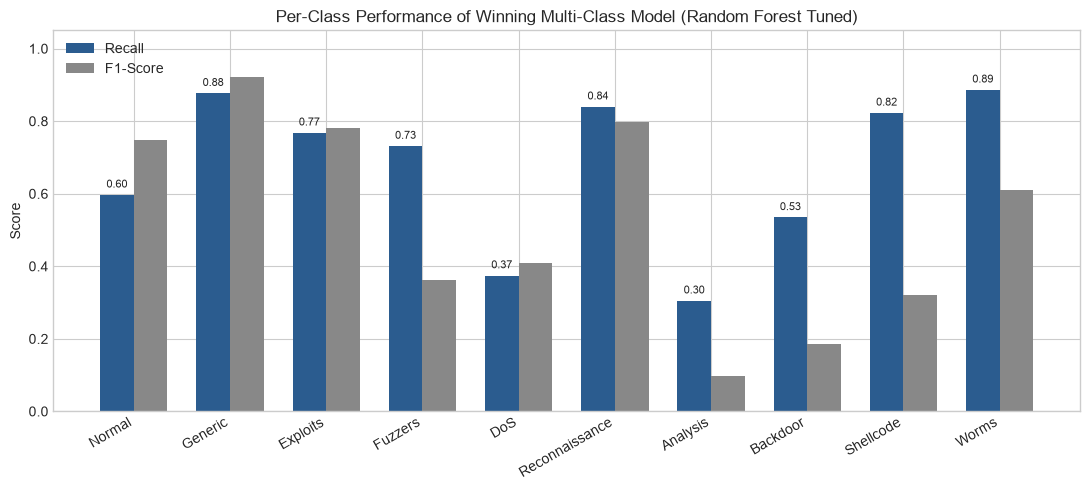

In [8]:
df_per_class = pd.read_csv(config.PER_CLASS_REPORT_PATH)
display(df_per_class)

# Plot Per-Class Recall and F1-Score
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(df_per_class))
width = 0.35

ax.bar(x - width/2, df_per_class['recall'], width, label='Recall', color='#2b5c8f')
ax.bar(x + width/2, df_per_class['f1_score'], width, label='F1-Score', color='#888888')

ax.set_ylabel('Score')
ax.set_title('Per-Class Performance of Winning Multi-Class Model (Random Forest Tuned)')
ax.set_xticks(x)
ax.set_xticklabels(df_per_class['class'], rotation=30, ha='right')
ax.set_ylim([0.0, 1.05])
ax.legend()

for i, v in enumerate(df_per_class['recall']):
    ax.text(i - width/2, v + 0.02, f'{v:.2f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

## 8. Normalized Confusion Matrix Heatmap

The 10x10 normalized confusion matrix illustrates the percentage of actual samples correctly identified for each class along the main diagonal, as well as specific cross-class confusion patterns.

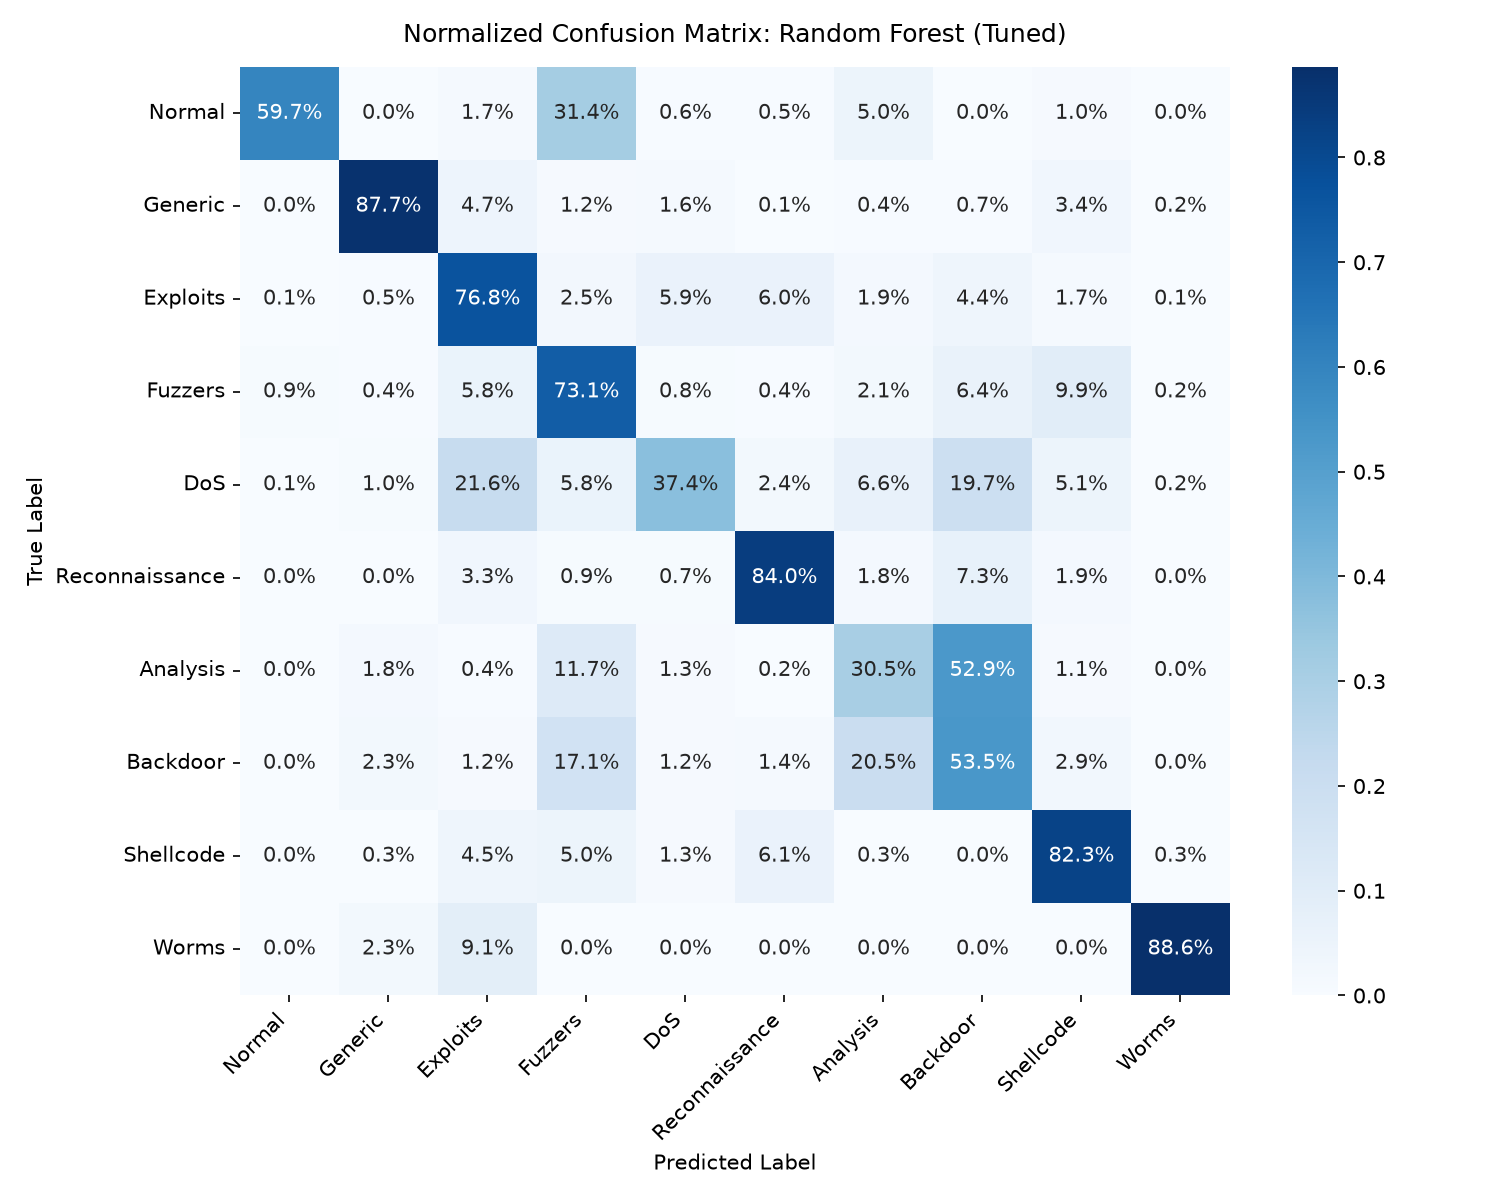

In [9]:
cm_figure_path = config.FIGURES_DIR / 'cm_multiclass_best.png'
if cm_figure_path.exists():
    display(Image(filename=str(cm_figure_path)))
else:
    print('Confusion matrix plot not found at:', cm_figure_path)

## 9. Verification of Cascade Inference Contract

In accordance with `architecture.md` Section 3.8 and Section 6.1:
1. The **binary classifier** operates as the first line of defense to flag malicious traffic (Normal vs Attack).
2. For records flagged as Attack, the **multi-class classifier** predicts class probabilities across categories and assigns the most likely specific attack type (`argmax over non-Normal classes`).
3. Normal rows receive category `"Normal"` directly.

We test this cascade workflow on `data/sample/sample_input.csv` (200 records).

In [10]:
sample_df = pd.read_csv(config.SAMPLE_INPUT_PATH)
best_binary = joblib.load(config.BEST_BINARY_MODEL_PATH)
best_multi = joblib.load(config.BEST_MULTICLASS_MODEL_PATH)

# Stage 1: Feature Transformation & Binary Inference
X_sample_full = preprocess.transform_features(preprocessor, sample_df[feature_cols])
binary_preds = best_binary.predict(X_sample_full)

# Stage 2: Multi-Class Attribution for Attack rows
categories = ['Normal'] * len(sample_df)
attack_indices = np.where(binary_preds == 1)[0]

if len(attack_indices) > 0:
    probs = best_multi.predict_proba(X_sample_full[attack_indices])
    non_normal_indices = [i for i, c in enumerate(best_multi.classes_) if c != 'Normal']
    sub_probs = probs[:, non_normal_indices]
    best_cat_indices = np.argmax(sub_probs, axis=1)
    for row_idx, cat_idx in zip(attack_indices, best_cat_indices):
        categories[row_idx] = best_multi.classes_[non_normal_indices[cat_idx]]

results_summary = pd.DataFrame({
    'Total Samples': [len(sample_df)],
    'Normal Count': [(binary_preds == 0).sum()],
    'Attack Count': [(binary_preds == 1).sum()],
})
display(results_summary)

print('Predicted Category Breakdown on Sample CSV:')
print(pd.Series(categories).value_counts())

,Total Samples,Normal Count,Attack Count
0,200,98,102


Predicted Category Breakdown on Sample CSV:
Normal            98
Fuzzers           29
Exploits          28
Generic           12
Reconnaissance     9
Backdoor           7
Analysis           7
DoS                7
Shellcode          3
Name: count, dtype: int64
